<a href="https://colab.research.google.com/github/Hermann-CC96/IA-Computacional/blob/main/Trabalho_2_(Classifica%C3%A7%C3%A3o).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Classificação - Qualidade de Vinho Tinto**

**Dataset:** Qualidade de Vinho Tinto (winequality-red.csv)

**Origem:** UCI Machine Learning Repository / Kaggle

**Problema:** Classificação Binária.

**Objetivo:** Diferente da tarefa anterior, o objetivo aqui não é prever a nota exata, mas sim classificar o vinho em duas categorias: "Bom" (1) ou "Ruim" (0).

**Atributos:** São utilizadas as mesmas 11 características físico-químicas (acidez, pH, álcool, etc.) para determinar a classe do vinho.

**Definição de Classes:**

Classe 0 (Ruim): Vinhos com nota de qualidade menor ou igual a 5.

Classe 1 (Bom): Vinhos com nota de qualidade maior que 5.

In [113]:
import pandas as pd

In [114]:
dados = pd.read_csv('/content/winequality-red.csv', delimiter =';')

In [115]:
dados.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [116]:
dados.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [117]:
dados.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


**Catogorização**

Criar a coluna de classificação (o alvo)


In [118]:
print(dados['quality'].value_counts())

quality
5    681
6    638
7    199
4     53
8     18
3     10
Name: count, dtype: int64


In [119]:
dados['Eh Bom'] = dados['quality'].apply(lambda x: 1 if x > 5 else 0)

In [120]:
print(dados['Eh Bom'].value_counts())

Eh Bom
1    855
0    744
Name: count, dtype: int64


Separar X (feature) e Y (alvo)

In [121]:
x = dados.iloc[:, :-1]
y = dados.iloc[:, -1]

In [122]:
x.shape, y.shape

((1599, 12), (1599,))

In [123]:
# Separar dados em treino e teste
from sklearn.model_selection import train_test_split

In [124]:
x_teste, x_treino, y_teste, y_treino = train_test_split(x, y, test_size=0.3, random_state=42)

Padronização de dados de treinamento e teste:

Permitindo calcular a distancias matematica entre os pontos de dados.


In [125]:
from sklearn.preprocessing import StandardScaler

In [126]:
scaler = StandardScaler()

In [127]:
x_treino = scaler.fit_transform(x_treino)
x_teste = scaler.transform(x_teste)

Criar a divisão de treino e teste:

Para definir como o modelo vai a aprender a separar os vinhos bons e ruim, a utilização de "rbf" foi necessario para traçar as curvas e formas complexas. Porém a quimica do vinho é complexa ou seja a relação entre os componentes de vinho tinto não é linear.

In [147]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.svm import SVC

In [148]:
modelo_lr = LogisticRegression()
modelo_svm = SVC(kernel='rbf', C = 1.0, random_state= 42)

In [149]:
print("\nDimensões dos dados:")
print(f"Treino: {x_treino.shape}")
print(f"Teste:  {x_teste.shape}")


Dimensões dos dados:
Treino: (480, 12)
Teste:  (1119, 12)


In [150]:
modelo_lr.fit(x_treino, y_treino)

LogisticRegression()

In [151]:
modelo_svm.fit(x_treino, y_treino)

SVC(random_state=42)

**Avaliação do SVM**

Matriz de Confusão (mostra quantos ele acertou e errou de cada tipo).

Classification Report (relatório com precisão, recall e f1-score).


In [152]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, mean_squared_error, r2_score

In [153]:
y_pred_lr = modelo_lr.predict(x_teste)
y_pred_svm = modelo_svm.predict(x_teste)

In [154]:
cm_svm = confusion_matrix(y_teste, y_pred_svm)

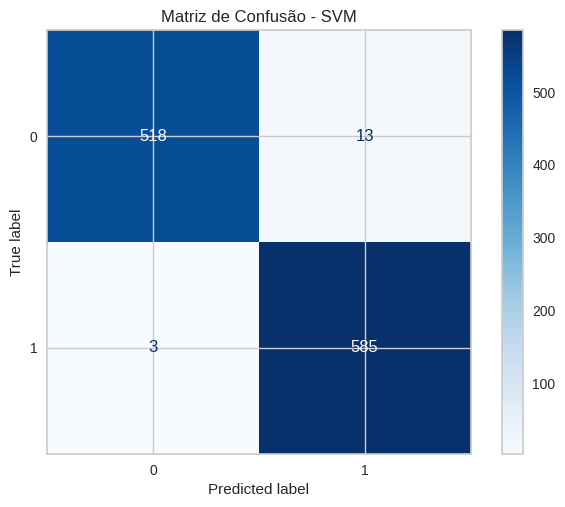

In [155]:

disp = ConfusionMatrixDisplay(confusion_matrix= cm_svm, display_labels=modelo_svm.classes_)
disp.plot(cmap = plt.cm.Blues)
plt.title('Matriz de Confusão - SVM')
plt.show()


In [156]:
mc_lr = confusion_matrix(y_teste, y_pred_lr)

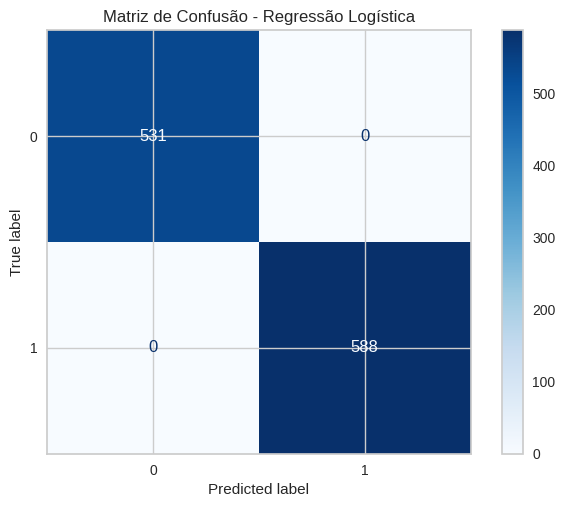

In [164]:
disp = ConfusionMatrixDisplay(confusion_matrix= mc_lr, display_labels=modelo_lr.classes_)
disp.plot(cmap = plt.cm.Blues)
plt.title('Matriz de Confusão - Regressão Logística')
plt.show()

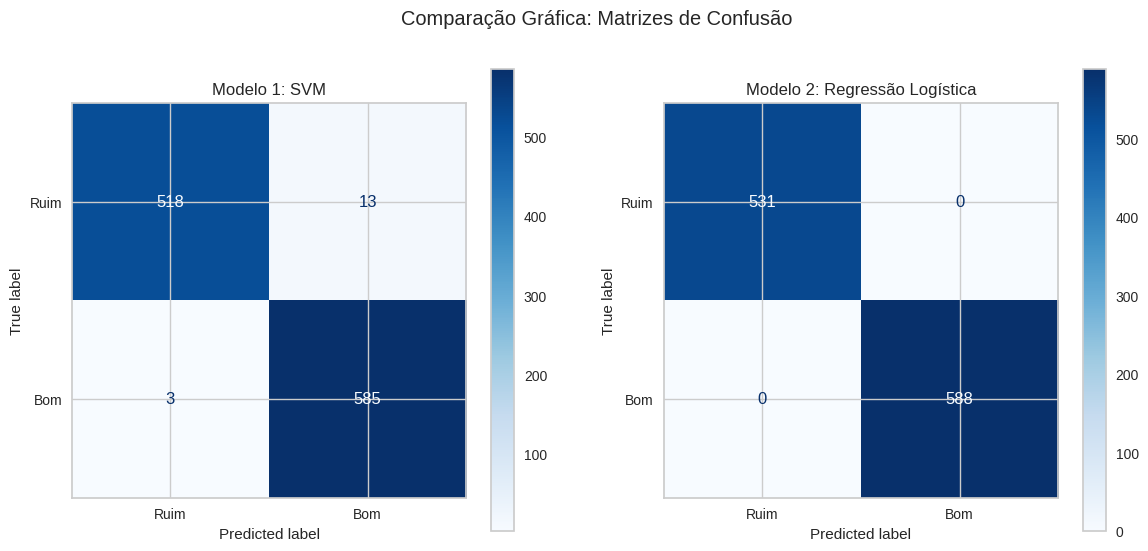

In [166]:
# --- Gerar os Gráficos Comparativos ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Gráfico 1: Matriz de Confusão do SVM
disp_svm = ConfusionMatrixDisplay.from_predictions(y_teste, y_pred_svm, display_labels=['Ruim', 'Bom'], cmap='Blues', ax=ax1)
ax1.set_title("Modelo 1: SVM")

# Gráfico 2: Matriz de Confusão da Regressão Logística
disp_lr = ConfusionMatrixDisplay.from_predictions(y_teste, y_pred_lr, display_labels=['Ruim', 'Bom'],  cmap='Blues', ax=ax2)
ax2.set_title("Modelo 2: Regressão Logística")

plt.suptitle("Comparação Gráfica: Matrizes de Confusão")
plt.show()

In [168]:
# Gerando dados estatísticos (desempenho dos modelos)
from sklearn.metrics import classification_report

In [169]:
print(classification_report(y_teste, y_pred_svm))

              precision    recall  f1-score   support

           0       0.99      0.98      0.98       531
           1       0.98      0.99      0.99       588

    accuracy                           0.99      1119
   macro avg       0.99      0.99      0.99      1119
weighted avg       0.99      0.99      0.99      1119



In [170]:
print(classification_report(y_teste, y_pred_lr))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       531
           1       1.00      1.00      1.00       588

    accuracy                           1.00      1119
   macro avg       1.00      1.00      1.00      1119
weighted avg       1.00      1.00      1.00      1119

